In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv("flight_data_ERA5.csv")

print("Dataset shape:", df.shape)

print("\nColumns:")
for col in df.columns:
    print(col)

display(df.head())

Dataset shape: (10642, 38)

Columns:
Used Date
From
To
Airline
Scheduled Departure
SDEP
DEP
SARR
ARR
Departure Delay
Distance
Passenger Load Factor
Airline Rating
Airport Rating
Market Share
OTP Index
Category
Departure_Hour
Scheduled_DateTime
Weather_Cutoff
Past_temperature
Past_windspeedKmph
Past_precipMM
Past_humidity
Past_pressure
Past_cloudcover
Past_weatherDesc
Hourly_Airport_Departures
Airport_Congestion_Index
Is_Weekend
Is_Delayed
temperature_2m
wind_speed_10m
precipitation
relative_humidity_2m
pressure_msl
cloud_cover
weather_code


,Used Date,From,To,Airline,Scheduled Departure,SDEP,DEP,SARR,ARR,Departure Delay,...,Airport_Congestion_Index,Is_Weekend,Is_Delayed,temperature_2m,wind_speed_10m,precipitation,relative_humidity_2m,pressure_msl,cloud_cover,weather_code
0,2019-01-02,BOM,DEL,Vistara,01:10,110,130,320,325,20,...,0.040698,0,1,21.6,10.9,0.0,71,1017.6,64,2
1,2019-01-09,DEL,HYD,Spicejet,22:05,2205,40,25,252,155,...,0.225806,0,1,18.3,7.4,0.0,45,1016.2,0,0
2,2019-01-22,CCU,DEL,SpiceJet,18:30,1830,1838,2055,2106,8,...,1.000000,0,1,28.0,3.3,0.0,40,1015.2,0,0
3,2019-01-23,CCU,DEL,SpiceJet,18:30,1830,1830,2055,2100,0,...,1.000000,0,0,28.9,4.0,0.0,37,1015.0,0,0
4,2019-01-24,CCU,DEL,SpiceJet,18:30,1830,1830,2055,2101,0,...,1.000000,0,0,29.2,4.5,0.0,42,1016.0,0,0


In [4]:
# Check missing values
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Check target distribution
print("\nTarget distribution:")
print(df["Is_Delayed"].value_counts())

print("\nTarget percentages:")
print(df["Is_Delayed"].value_counts(normalize=True) * 100)

# Check feature data types
print("\nColumn data types:")
print(df.dtypes.to_string())

Missing values:
Hourly_Airport_Departures    69
Airport_Congestion_Index     69
dtype: int64

Target distribution:
Is_Delayed
0    5471
1    5171
Name: count, dtype: int64

Target percentages:
Is_Delayed
0    51.409509
1    48.590491
Name: proportion, dtype: float64

Column data types:
Used Date                     object
From                          object
To                            object
Airline                       object
Scheduled Departure           object
SDEP                           int64
DEP                            int64
SARR                           int64
ARR                            int64
Departure Delay                int64
Distance                       int64
Passenger Load Factor        float64
Airline Rating               float64
Airport Rating               float64
Market Share                 float64
OTP Index                    float64
Category                       int64
Departure_Hour                 int64
Scheduled_DateTime            object
Weather_Cu

In [5]:
# Select initial features
features = ["Departure_Hour", "Is_Weekend", "Distance"]

# Feature matrix and target labels
X = df[features].to_numpy()
y = df["Is_Delayed"].to_numpy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFirst 5 feature vectors:")
print(X[:5])

print("\nFirst 5 labels:")
print(y[:5])

X shape: (10642, 3)
y shape: (10642,)

First 5 feature vectors:
[[   1    0 1138]
 [  22    0 1244]
 [  18    0 1312]
 [  18    0 1312]
 [  18    0 1312]]

First 5 labels:
[1 1 1 0 0]


In [6]:
from sklearn.model_selection import StratifiedKFold

# Create 5-fold cross-validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Inspect the folds
for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
    print(f"Fold {fold}:")
    print(f"  Training flights: {len(train_idx)}")
    print(f"  Validation flights: {len(val_idx)}")

Fold 1:
  Training flights: 8513
  Validation flights: 2129
Fold 2:
  Training flights: 8513
  Validation flights: 2129
Fold 3:
  Training flights: 8514
  Validation flights: 2128
Fold 4:
  Training flights: 8514
  Validation flights: 2128
Fold 5:
  Training flights: 8514
  Validation flights: 2128


In [7]:
from sklearn.preprocessing import StandardScaler

# Use the first fold to demonstrate preprocessing
train_idx, val_idx = next(skf.split(X, y))

# Separate training and validation data
# Convert to float so standardized values retain decimals
X_train = X[train_idx].astype(float).copy()
X_val = X[val_idx].astype(float).copy()

y_train = y[train_idx]
y_val = y[val_idx]

# Standardize Departure_Hour (column 0) and Distance (column 2)
scaler = StandardScaler()

X_train[:, [0, 2]] = scaler.fit_transform(X_train[:, [0, 2]])
X_val[:, [0, 2]] = scaler.transform(X_val[:, [0, 2]])

# Display results
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

print("\nFirst 5 standardized training rows:")
print(X_train[:5])

Training shape: (8513, 3)
Validation shape: (2129, 3)

First 5 standardized training rows:
[[-1.88601721  0.         -0.46160073]
 [ 1.38429273  0.         -0.13019781]
 [ 0.76137655  0.          0.08240029]
 [ 0.76137655  0.          0.08240029]
 [ 0.76137655  0.          0.08240029]]


In [8]:
# Initialize weights and biases
rng = np.random.default_rng(42)

W = rng.normal(0, 0.01, size=(2, 3))
b = np.zeros(2)

# Calculate scores for the first 5 training flights
scores = X_train[:5] @ W.T + b

print("Weight matrix shape:", W.shape)
print("Bias shape:", b.shape)

print("\nInitial weights:")
print(W)

print("\nClass scores for first 5 flights:")
print(scores)

print("\nPredicted classes:")
print(np.argmax(scores, axis=1))

print("\nActual classes:")
print(y_train[:5])

Weight matrix shape: (2, 3)
Bias shape: (2,)

Initial weights:
[[ 0.00304717 -0.01039984  0.00750451]
 [ 0.00940565 -0.01951035 -0.0130218 ]]

Class scores for first 5 flights:
[[-0.0092111  -0.01172834]
 [ 0.00324111  0.01471558]
 [ 0.00293842  0.00608824]
 [ 0.00293842  0.00608824]
 [ 0.00293842  0.00608824]]

Predicted classes:
[0 1 1 1 1]

Actual classes:
[1 1 1 0 0]


In [9]:
def svm_loss(scores, y):
    # Score of the correct class for each flight
    correct_scores = scores[np.arange(len(y)), y]

    # Compare each class score against the correct score
    margins = np.maximum(
        0,
        scores - correct_scores[:, None] + 1
    )

    # Correct class should not contribute to loss
    margins[np.arange(len(y)), y] = 0

    # Average loss across all flights
    return np.mean(np.sum(margins, axis=1))


# Calculate loss for the first 5 flights
loss = svm_loss(scores, y_train[:5])

print("Initial SVM loss:", loss)

Initial SVM loss: 0.9988385171826337


In [35]:
def train_linear_svm(X_train, y_train, learning_rate=0.01, epochs=500, reg_strength=0.01):

    n_samples, n_features = X_train.shape
    n_classes = 2

    # Initialize weights and biases
    rng = np.random.default_rng(42)
    W = rng.normal(0, 0.01, size=(n_classes, n_features))
    b = np.zeros(n_classes)

    loss_history = []

    for epoch in range(epochs):

        # 1. Calculate class scores
        scores = X_train @ W.T + b

        # 2. Calculate hinge loss + L2 penalty
        hinge_loss = svm_loss(scores, y_train)
        l2_penalty = (reg_strength / 2) * np.sum(W ** 2)

        total_loss = hinge_loss + l2_penalty
        loss_history.append(total_loss)

        # 3. Calculate margins
        correct_scores = scores[np.arange(n_samples), y_train]

        margins = scores - correct_scores[:, None] + 1
        margins[np.arange(n_samples), y_train] = 0

        # 4. Identify margin violations
        active = (margins > 0).astype(float)
        active[np.arange(n_samples), y_train] = -np.sum(active, axis=1)

        # 5. Calculate gradients, including L2
        dW = (active.T @ X_train / n_samples) + reg_strength * W
        db = np.mean(active, axis=0)

        # 6. Update weights and biases
        W -= learning_rate * dW
        b -= learning_rate * db

    return W, b, loss_history

In [11]:
# Train linear SVM on first fold
W_trained, b_trained, loss_history = train_linear_svm(
    X_train,
    y_train,
    learning_rate=0.01,
    epochs=500
)

print("Initial loss:", loss_history[0])
print("Final loss:", loss_history[-1])

# Evaluate on validation fold
y_pred = predict_linear_svm(X_val, W_trained, b_trained)

from sklearn.metrics import accuracy_score, classification_report

print("\nValidation accuracy:", accuracy_score(y_val, y_pred))
print("\nClassification report:")
print(classification_report(y_val, y_pred))

Initial loss: 0.9985233410370954
Final loss: 0.9027021951618567

Validation accuracy: 0.5608266791921089

Classification report:
              precision    recall  f1-score   support

           0       0.58      0.55      0.56      1094
           1       0.55      0.57      0.56      1035

    accuracy                           0.56      2129
   macro avg       0.56      0.56      0.56      2129
weighted avg       0.56      0.56      0.56      2129



In [36]:
from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import pandas as pd
import matplotlib.pyplot as plt


def evaluate_linear_svm(df, features, learning_rate=0.01,
                        epochs=500, reg_strength=0.01):

    X = df[features]
    y = df["Is_Delayed"].to_numpy()

    # Identify numerical and categorical features
    categorical_features = X.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    numerical_features = [
        col for col in features if col not in categorical_features
    ]

    # 5-fold stratified cross-validation
    skf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    results = []
    all_true = []
    all_pred = []

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):

        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y[train_idx]
        y_val = y[val_idx]

        # Standardize numerical features and encode categorical features
        # Fit preprocessing on training fold only
        preprocessor = ColumnTransformer(
            transformers=[
                ("num", StandardScaler(), numerical_features),
                ("cat", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ), categorical_features)
            ]
        )

        X_train = preprocessor.fit_transform(X_train)
        X_val = preprocessor.transform(X_val)

        # Train linear SVM with L2 regularization
        W, b, loss_history = train_linear_svm(
            X_train,
            y_train,
            learning_rate=learning_rate,
            epochs=epochs,
            reg_strength=reg_strength
        )

        # Predict validation flights
        y_pred = predict_linear_svm(X_val, W, b)

        # Store predictions for combined confusion matrix
        all_true.extend(y_val)
        all_pred.extend(y_pred)

        # Calculate metrics for each fold
        results.append({
            "Fold": fold,
            "Accuracy": accuracy_score(y_val, y_pred),
            "Precision": precision_score(y_val, y_pred, zero_division=0),
            "Recall": recall_score(y_val, y_pred, zero_division=0),
            "F1": f1_score(y_val, y_pred, zero_division=0)
        })

    results_df = pd.DataFrame(results)

    print("Results for each fold:")
    display(results_df.round(4))

    print("\nAverage across 5 folds:")
    print(
        results_df[["Accuracy", "Precision", "Recall", "F1"]]
        .mean()
        .round(4)
    )

    # Combined confusion matrix across all 5 folds
    cm = confusion_matrix(all_true, all_pred, labels=[0, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Delayed", "Delayed"]
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title("Linear SVM - 5-Fold Cross-Validation")
    plt.show()

    return results_df

Results for each fold:


,Fold,Accuracy,Precision,Recall,F1
0,1,0.5622,0.5473,0.5758,0.5612
1,2,0.5571,0.5455,0.5280,0.5366
2,3,0.5667,0.5528,0.5667,0.5597
3,4,0.5479,0.5352,0.5300,0.5326
4,5,0.5719,0.5595,0.5590,0.5593



Average across 5 folds:
Accuracy     0.5612
Precision    0.5481
Recall       0.5519
F1           0.5499
dtype: float64


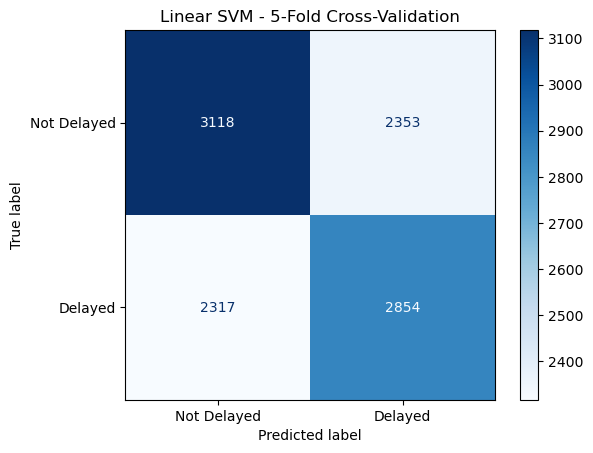

In [16]:
features = ["Departure_Hour", "Is_Weekend", "Distance"]

results_model1 = evaluate_linear_svm(df, features)

Results for each fold:


,Fold,Accuracy,Precision,Recall,F1
0,1,0.5777,0.5596,0.6164,0.5867
1,2,0.5749,0.5602,0.5803,0.5701
2,3,0.5794,0.5627,0.6035,0.5824
3,4,0.5672,0.5528,0.5725,0.5625
4,5,0.5780,0.5623,0.5938,0.5776



Average across 5 folds:
Accuracy     0.5755
Precision    0.5595
Recall       0.5933
F1           0.5758
dtype: float64


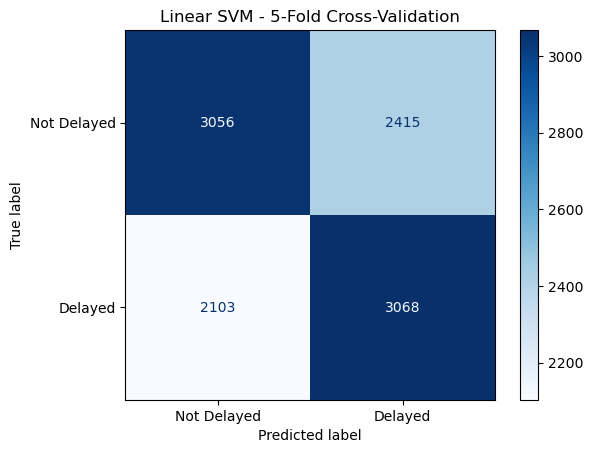

In [17]:
features_model2 = [
    "Departure_Hour",
    "Is_Weekend",
    "Distance",
    "Past_temperature",
    "Past_windspeedKmph",
    "Past_precipMM",
    "Past_humidity"
]

results_model2 = evaluate_linear_svm(df, features_model2)

In [18]:
for col in ["Airline", "From", "To"]:
    print(f"{col}: {df[col].nunique()} unique categories")
    print(df[col].value_counts().head())
    print()

Airline: 7 unique categories
Airline
Indigo       4021
Air India    1592
Vistara      1533
Air Asia     1311
Spicejet     1005
Name: count, dtype: int64

From: 4 unique categories
From
BLR    5393
CCU    2181
DEL    2041
BOM    1027
Name: count, dtype: int64

To: 3 unique categories
To
DEL    6092
BOM    2509
HYD    2041
Name: count, dtype: int64



Results for each fold:


,Fold,Accuracy,Precision,Recall,F1
0,1,0.6242,0.6137,0.6126,0.6132
1,2,0.6379,0.6239,0.6402,0.6320
2,3,0.6339,0.6244,0.6190,0.6217
3,4,0.6405,0.6240,0.6547,0.6390
4,5,0.6273,0.6167,0.6161,0.6164



Average across 5 folds:
Accuracy     0.6328
Precision    0.6205
Recall       0.6285
F1           0.6244
dtype: float64


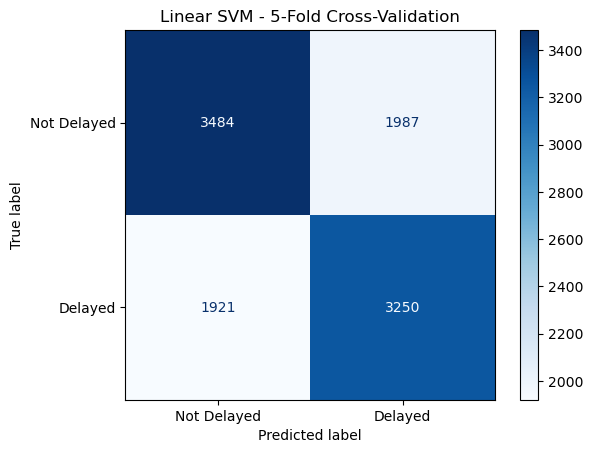

In [20]:
features_model3 = [
    "Departure_Hour",
    "Is_Weekend",
    "Distance",
    "Past_temperature",
    "Past_windspeedKmph",
    "Past_precipMM",
    "Past_humidity",
    "Airline",
    "From",
    "To"
]

results_model3 = evaluate_linear_svm(df, features_model3)

Results for each fold:


,Fold,Accuracy,Precision,Recall,F1
0,1,0.5388,0.5237,0.5662,0.5441
1,2,0.5500,0.5354,0.5551,0.5451
2,3,0.5658,0.5494,0.5919,0.5698
3,4,0.5517,0.5365,0.5687,0.5521
4,5,0.5367,0.5212,0.5716,0.5452



Average across 5 folds:
Accuracy     0.5486
Precision    0.5332
Recall       0.5707
F1           0.5513
dtype: float64


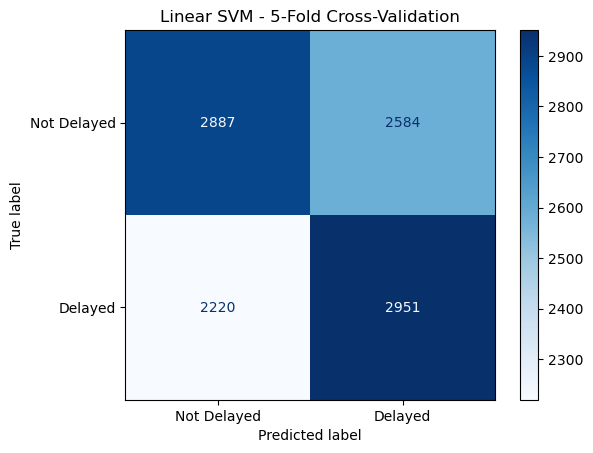

In [22]:
features_model4 = [
    "Past_pressure",
    "Past_cloudcover",
    "Past_weatherDesc"
]

results_model4 = evaluate_linear_svm(df, features_model4)

Results for each fold:


,Fold,Accuracy,Precision,Recall,F1
0,1,0.6252,0.6177,0.6010,0.6092
1,2,0.6299,0.6218,0.6074,0.6145
2,3,0.6325,0.6283,0.5967,0.6121
3,4,0.6391,0.6294,0.6257,0.6275
4,5,0.6212,0.6159,0.5861,0.6006



Average across 5 folds:
Accuracy     0.6296
Precision    0.6226
Recall       0.6034
F1           0.6128
dtype: float64


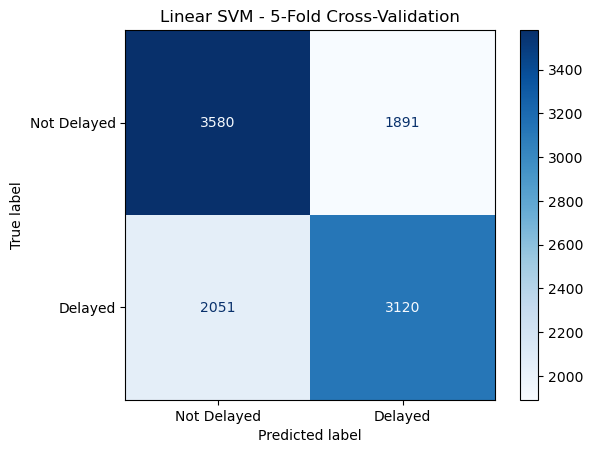

In [25]:
features_model5 = [
    # Flight information
    "Departure_Hour",
    "Is_Weekend",
    "Distance",

    

    # Airline and airport information
    "Airline",
    "From",
    "To"
]

results_model5 = evaluate_linear_svm(df, features_model5)

Results for each fold:


,Fold,Accuracy,Precision,Recall,F1
0,1,0.6008,0.5961,0.5546,0.5746
1,2,0.6233,0.6193,0.5822,0.6002
2,3,0.6057,0.5992,0.5696,0.5840
3,4,0.5987,0.5949,0.5455,0.5691
4,5,0.6062,0.5992,0.5725,0.5856



Average across 5 folds:
Accuracy     0.6069
Precision    0.6017
Recall       0.5649
F1           0.5827
dtype: float64


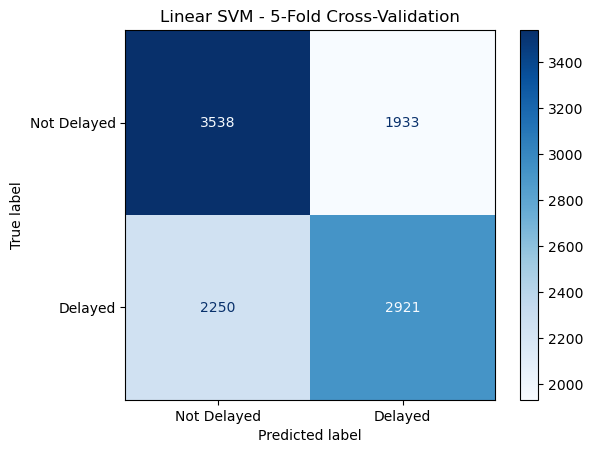

In [32]:
features_model6 = [
    "Departure_Hour",
    "Is_Weekend",
    "Distance",
    "Airline",
    "From",
    "To",
    "Passenger Load Factor",
    "Airline Rating",
    "Airport Rating",
    "Market Share",
    "OTP Index"
]

results_model6 = evaluate_linear_svm(df, features_model6)

Results for each fold:


,Fold,Accuracy,Precision,Recall,F1
0,1,0.5970,0.5857,0.5845,0.5851
1,2,0.6045,0.5920,0.5977,0.5948
2,3,0.6081,0.5947,0.6074,0.6010
3,4,0.6109,0.5972,0.6122,0.6046
4,5,0.6043,0.5909,0.6035,0.5971



Average across 5 folds:
Accuracy     0.6050
Precision    0.5921
Recall       0.6010
F1           0.5965
dtype: float64


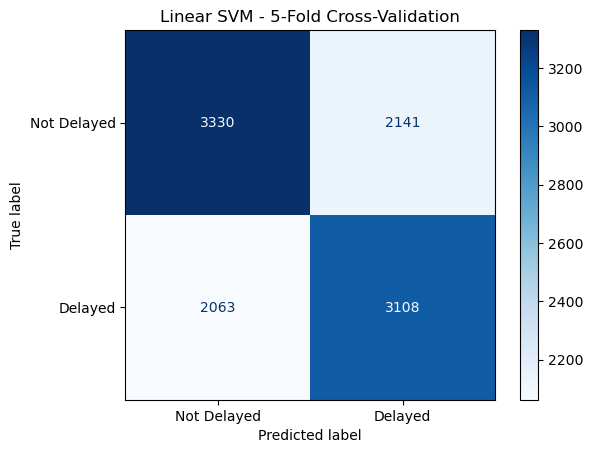

In [33]:
results_model3_2000 = evaluate_linear_svm(
    df,
    features_model3,
    learning_rate=0.01,
    epochs=2000
)

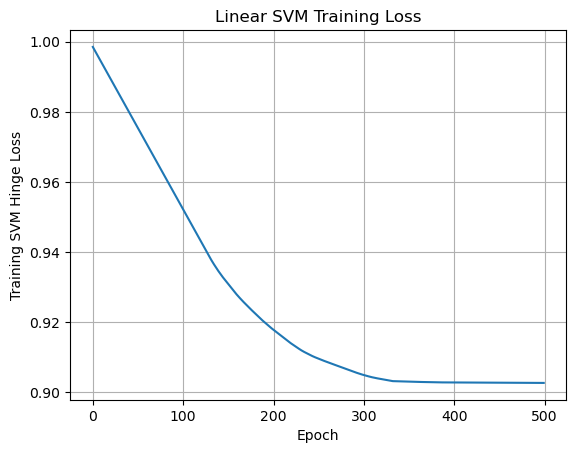

In [34]:
import matplotlib.pyplot as plt

plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Training SVM Hinge Loss")
plt.title("Linear SVM Training Loss")
plt.grid(True)
plt.show()

Results for each fold:


,Fold,Accuracy,Precision,Recall,F1
0,1,0.6275,0.6177,0.6135,0.6156
1,2,0.6397,0.6263,0.6402,0.6332
2,3,0.6335,0.6248,0.6151,0.6199
3,4,0.6372,0.6215,0.6480,0.6345
4,5,0.6264,0.6159,0.6141,0.6150



Average across 5 folds:
Accuracy     0.6329
Precision    0.6212
Recall       0.6262
F1           0.6236
dtype: float64


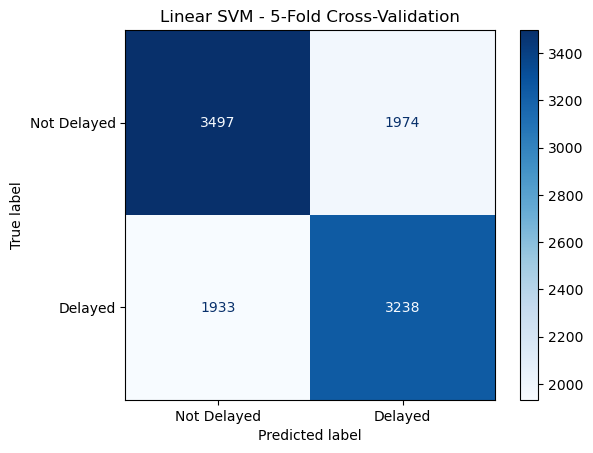

In [37]:
results_model3_l2 = evaluate_linear_svm(
    df,
    features_model3,
    learning_rate=0.01,
    epochs=500,
    reg_strength=0.01
)

Results for each fold:


,Fold,Accuracy,Precision,Recall,F1
0,1,0.6252,0.6149,0.6126,0.6137
1,2,0.6383,0.6245,0.6402,0.6323
2,3,0.6339,0.6241,0.6199,0.6220
3,4,0.6396,0.6233,0.6528,0.6377
4,5,0.6273,0.6167,0.6161,0.6164



Average across 5 folds:
Accuracy     0.6329
Precision    0.6207
Recall       0.6283
F1           0.6244
dtype: float64


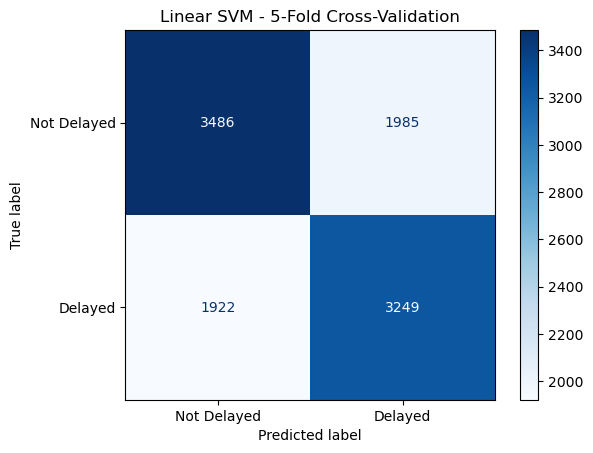

Results for each fold:


,Fold,Accuracy,Precision,Recall,F1
0,1,0.6322,0.6226,0.6184,0.6205
1,2,0.6402,0.6276,0.6373,0.6324
2,3,0.6335,0.6243,0.6170,0.6206
3,4,0.6292,0.6172,0.6238,0.6205
4,5,0.6245,0.6146,0.6093,0.6119



Average across 5 folds:
Accuracy     0.6319
Precision    0.6213
Recall       0.6212
F1           0.6212
dtype: float64


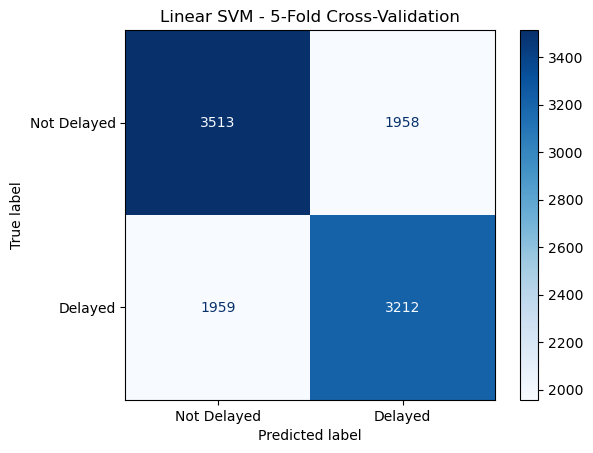

In [38]:
results_l2_001 = evaluate_linear_svm(
    df, features_model3,
    learning_rate=0.01,
    epochs=500,
    reg_strength=0.001
)

results_l2_01 = evaluate_linear_svm(
    df, features_model3,
    learning_rate=0.01,
    epochs=500,
    reg_strength=0.1
)


Learning Rate: 0.001
Results for each fold:


,Fold,Accuracy,Precision,Recall,F1
0,1,0.6026,0.6090,0.5101,0.5552
1,2,0.5956,0.6043,0.4845,0.5378
2,3,0.5893,0.5935,0.4913,0.5376
3,4,0.5898,0.5953,0.4865,0.5354
4,5,0.5935,0.5986,0.4961,0.5426



Average across 5 folds:
Accuracy     0.5942
Precision    0.6001
Recall       0.4937
F1           0.5417
dtype: float64


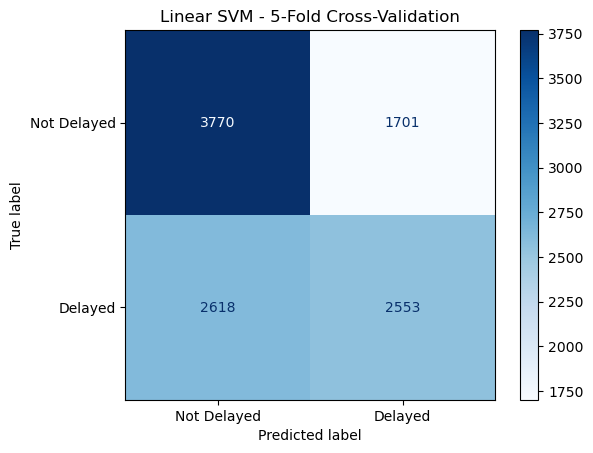


Learning Rate: 0.01
Results for each fold:


,Fold,Accuracy,Precision,Recall,F1
0,1,0.6252,0.6149,0.6126,0.6137
1,2,0.6383,0.6245,0.6402,0.6323
2,3,0.6339,0.6241,0.6199,0.6220
3,4,0.6396,0.6233,0.6528,0.6377
4,5,0.6273,0.6167,0.6161,0.6164



Average across 5 folds:
Accuracy     0.6329
Precision    0.6207
Recall       0.6283
F1           0.6244
dtype: float64


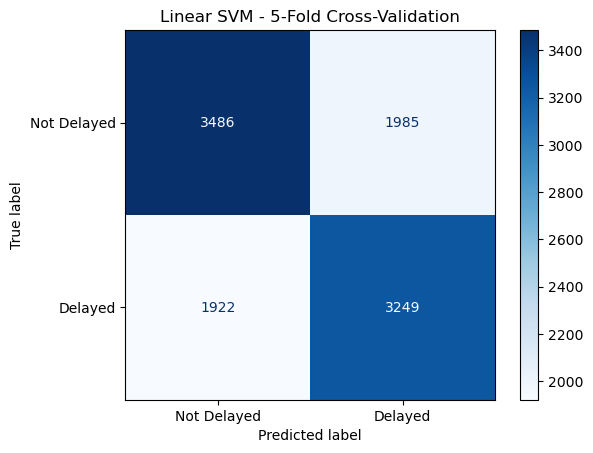


Learning Rate: 0.05
Results for each fold:


,Fold,Accuracy,Precision,Recall,F1
0,1,0.5970,0.5857,0.5845,0.5851
1,2,0.6045,0.5920,0.5977,0.5948
2,3,0.6081,0.5947,0.6074,0.6010
3,4,0.6109,0.5972,0.6122,0.6046
4,5,0.6043,0.5909,0.6035,0.5971



Average across 5 folds:
Accuracy     0.6050
Precision    0.5921
Recall       0.6010
F1           0.5965
dtype: float64


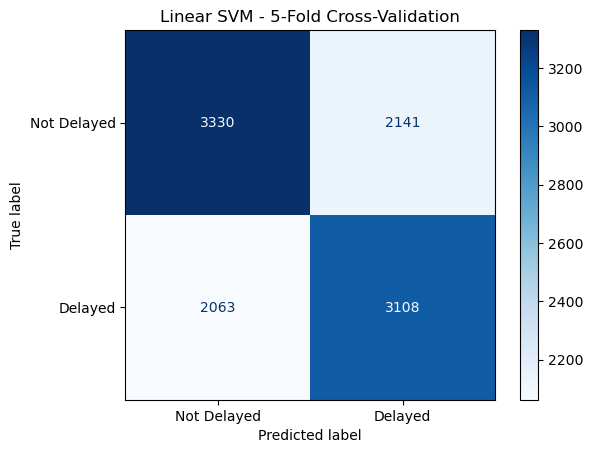


FINAL LEARNING RATE COMPARISON:


,Learning Rate,Accuracy,Precision,Recall,F1
0,0.001,0.5942,0.6001,0.4937,0.5417
1,0.010,0.6329,0.6207,0.6283,0.6244
2,0.050,0.6050,0.5921,0.6010,0.5965


In [39]:
learning_rates = [0.001, 0.01, 0.05]

lr_results = []

for lr in learning_rates:

    print(f"\n{'='*40}")
    print(f"Learning Rate: {lr}")
    print(f"{'='*40}")

    results = evaluate_linear_svm(
        df,
        features_model3,
        learning_rate=lr,
        epochs=500,
        reg_strength=0.001
    )

    averages = results[
        ["Accuracy", "Precision", "Recall", "F1"]
    ].mean()

    lr_results.append({
        "Learning Rate": lr,
        "Accuracy": averages["Accuracy"],
        "Precision": averages["Precision"],
        "Recall": averages["Recall"],
        "F1": averages["F1"]
    })

# Compare all learning rates
lr_comparison = pd.DataFrame(lr_results)

print("\nFINAL LEARNING RATE COMPARISON:")
display(lr_comparison.round(4))

Results for each fold:


,Fold,Accuracy,Precision,Recall,F1
0,1,0.6252,0.6149,0.6126,0.6137
1,2,0.6383,0.6245,0.6402,0.6323
2,3,0.6339,0.6241,0.6199,0.6220
3,4,0.6396,0.6233,0.6528,0.6377
4,5,0.6273,0.6167,0.6161,0.6164



Average across 5 folds:
Accuracy     0.6329
Precision    0.6207
Recall       0.6283
F1           0.6244
dtype: float64


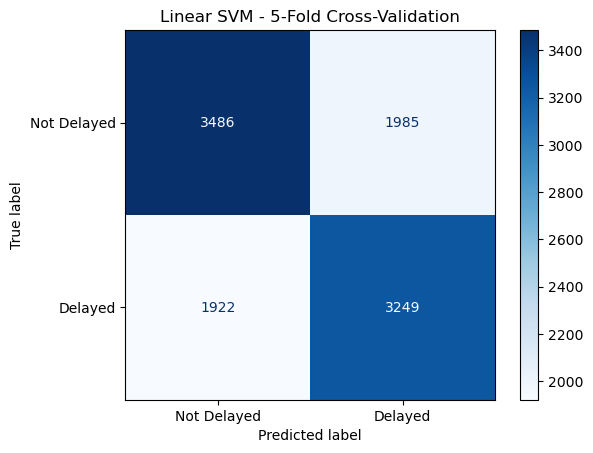

In [40]:
# FINAL LINEAR SVM MODEL

features_final = [
    "Departure_Hour",
    "Is_Weekend",
    "Distance",
    "Past_temperature",
    "Past_windspeedKmph",
    "Past_precipMM",
    "Past_humidity",
    "Airline",
    "From",
    "To"
]

final_svm_results = evaluate_linear_svm(
    df,
    features_final,
    learning_rate=0.01,
    epochs=500,
    reg_strength=0.001
)